In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import make_blobs

In [5]:
x, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, random_state=42)
x.shape, y.shape, x[:5], y[:5]

((100, 2),
 (100,),
 array([[-4.18630746,  8.36447971],
        [ 8.43055819,  5.66147687],
        [-4.41453716,  9.40251519],
        [ 7.5170894 ,  8.61194512],
        [ 5.43598861,  6.54816932]]),
 array([0, 1, 0, 1, 1]))

In [6]:
y= y * 2. - 1
y[:10]

array([-1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1., -1.])

In [7]:
np.random.seed(42)
w = np.random.rand(2,)
b = np.random.rand()
w, b

(array([0.37454012, 0.95071431]), 0.7319939418114051)

In [8]:
def predict(x, w, b):
    return np.sign(np.array(x) @ np.array(w) + b)

In [9]:
predict(x[:10], w, b)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

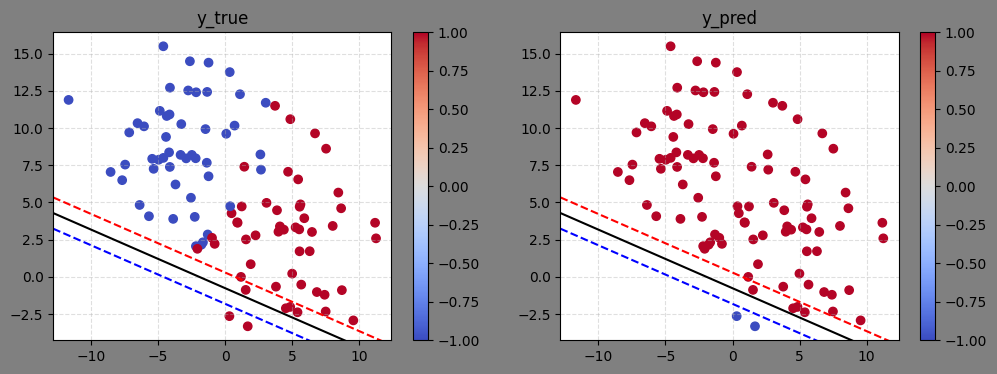

In [10]:
def plot_tvp(x, y, w, b):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), facecolor='grey')
    ax1.grid(linestyle='--', alpha=0.4)
    ax2.grid(linestyle='--', alpha=0.4)
    
    scat1 = ax1.scatter(x=x[:, 0], y=x[:, 1], c=y, cmap='coolwarm')
    ax1.set_title('y_true')
    plt.colorbar(scat1, ax=ax1)
    
    scat2 = ax2.scatter(x=x[:, 0], y=x[:, 1], c=predict(x, w, b), cmap='coolwarm')
    ax2.set_title('y_pred')
    plt.colorbar(scat2, ax=ax2)
    
    x_lims = np.array(ax1.get_xlim())
    y_lims = np.array(ax1.get_ylim())
    
    def get_y(val, target, w, b):
        return (target - b - (w[0] * val)) / w[1]
    
    # Plot lines on both
    for ax in [ax1, ax2]:
        ax.plot(x_lims, get_y(x_lims, 1, w, b), c='red', label='Upper Margin', linestyle='--')
        ax.plot(x_lims, get_y(x_lims, 0, w, b), c='black', label='Decision Boundary')
        ax.plot(x_lims, get_y(x_lims, -1, w, b), c='blue', label='Lower Margin', linestyle='--')

    ax1.set_xlim(x_lims)
    ax1.set_ylim(y_lims)

    ax2.set_xlim(x_lims)
    ax2.set_ylim(y_lims)

plot_tvp(x, y, w, b)

In [11]:
def hinge_loss(x, y, w, b):
    return np.maximum(0, 1 - y * (np.dot(x, w) + b))
hinge_loss([0, 0], -1, w, b)

1.731993941811405

In [12]:
def loss(x, y, w, b, c=1):
    return c * (1/x.shape[0]) * sum(hinge_loss(x, y, w, b)) + 0.5 * np.dot(w, w)
#loss(x, y, w, b)

In [13]:
def gradient_descent(x, y, w, b, l, c=1):
    """
    Derivative of the loss function:
    w - c * sum(0 if hinge_loss == 0 else yx)
    """
    hinge_grad = y[:, np.newaxis] * np.hstack((x, np.ones((x.shape[0], 1)))) # stack the ones on the end for the bias grad
    hinge_grad[hinge_loss(x, y, w, b) == 0] = 0.0
    wgrad = w - c * (1/x.shape[0]) * np.sum(hinge_grad[:, 0:len(w)], axis=0)
    bgrad = -c * (1/x.shape[0]) * np.sum(hinge_grad[:, len(w)])
    return w - l * wgrad, b - l * bgrad

In [14]:
epochs = 100000
L = 0.001

for i in range(epochs):
    w, b = gradient_descent(x, y, w, b, l=L)
    if i % 5000 == 4999:
        print(f"Epoch: {i+1:05d} | w1: {w[0]:.4f} | w2: {w[1]:.4f} | b: {b:.4f} | Loss: {loss(x, y, w, b):.4f}")

Epoch: 05000 | w1: 0.2819 | w2: -0.1611 | b: 0.6657 | Loss: 0.2349
Epoch: 10000 | w1: 0.2818 | w2: -0.1613 | b: 0.6683 | Loss: 0.2349
Epoch: 15000 | w1: 0.2818 | w2: -0.1613 | b: 0.6683 | Loss: 0.2349
Epoch: 20000 | w1: 0.2818 | w2: -0.1612 | b: 0.6683 | Loss: 0.2349
Epoch: 25000 | w1: 0.2818 | w2: -0.1612 | b: 0.6683 | Loss: 0.2349
Epoch: 30000 | w1: 0.2817 | w2: -0.1611 | b: 0.6683 | Loss: 0.2349
Epoch: 35000 | w1: 0.2817 | w2: -0.1613 | b: 0.6683 | Loss: 0.2349
Epoch: 40000 | w1: 0.2817 | w2: -0.1613 | b: 0.6683 | Loss: 0.2349
Epoch: 45000 | w1: 0.2817 | w2: -0.1612 | b: 0.6683 | Loss: 0.2349
Epoch: 50000 | w1: 0.2817 | w2: -0.1611 | b: 0.6683 | Loss: 0.2349
Epoch: 55000 | w1: 0.2816 | w2: -0.1611 | b: 0.6683 | Loss: 0.2349
Epoch: 60000 | w1: 0.2816 | w2: -0.1612 | b: 0.6683 | Loss: 0.2349
Epoch: 65000 | w1: 0.2817 | w2: -0.1612 | b: 0.6683 | Loss: 0.2349
Epoch: 70000 | w1: 0.2817 | w2: -0.1612 | b: 0.6683 | Loss: 0.2349
Epoch: 75000 | w1: 0.2818 | w2: -0.1611 | b: 0.6683 | Loss: 0.

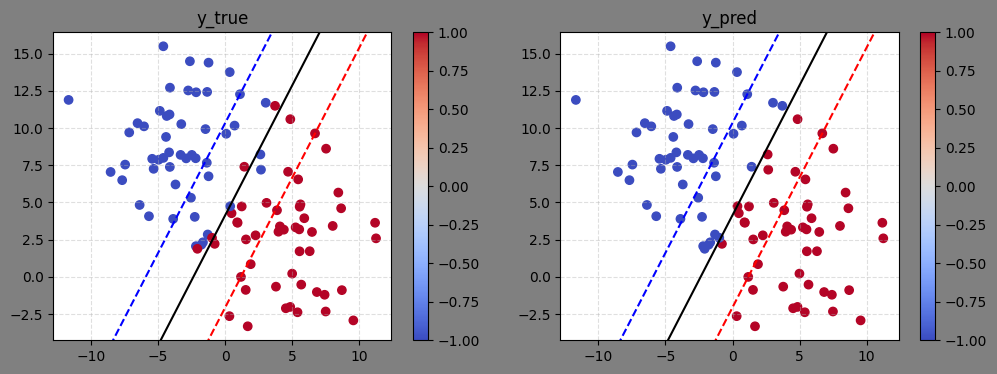

In [15]:
plot_tvp(x, y, w, b)

In [16]:
print(f"Score: {sum(predict(x, w, b) == y) / len(y)}")

Score: 0.93


# 3D Data

In [17]:
def plot_tvp_3d(x, y, w, b):
    # 1. Define the range of your data for the x and y axes
    x_min, x_max = x[:, 0].min(), x[:, 0].max()
    y_min, y_max = x[:, 1].min(), x[:, 1].max()
    
    # 2. Create a 10x10 grid of points across that range
    x_coords = np.linspace(x_min, x_max, 10)
    y_coords = np.linspace(y_min, y_max, 10)
    X_mesh, Y_mesh = np.meshgrid(x_coords, y_coords)
    
    # 3. Calculate the Z height for every point on the grid
    # Using your weights: w = [w1, w2, w3]
    Z_mesh = (-w[0] * X_mesh - w[1] * Y_mesh - b) / w[2]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), subplot_kw={'projection': '3d'}, facecolor='grey')

    # Plot the actual data points
    scat1 = ax1.scatter3D(x[:, 0], x[:, 1], x[:, 2], c=y, cmap='coolwarm', edgecolors='k')
    ax1.set_title('y_true')
    plt.colorbar(scat1, ax=ax1)
    
    scat2 = ax2.scatter3D(x[:, 0], x[:, 1], x[:, 2], c=predict(x, w, b), cmap='coolwarm', edgecolors='k')
    ax2.set_title('y_pred')
    plt.colorbar(scat2, ax=ax2)
    
    # Plot the Decision Plane
    # alpha=0.5 makes it semi-transparent so you can see points "behind" it
    ax1.plot_surface(X_mesh, Y_mesh, Z_mesh, alpha=0.6, color='gray')
    ax2.plot_surface(X_mesh, Y_mesh, Z_mesh, alpha=0.6, color='gray')
    # Optional: Add the Margins (+1 and -1)
    # Simply change the '0' in the numerator to 1 or -1
    Z_upper = (1 - w[0] * X_mesh - w[1] * Y_mesh - b) / w[2]
    Z_lower = (-1 - w[0] * X_mesh - w[1] * Y_mesh - b) / w[2]
    
    ax1.plot_surface(X_mesh, Y_mesh, Z_upper, alpha=0.4, color='red')
    ax1.plot_surface(X_mesh, Y_mesh, Z_lower, alpha=0.4, color='blue')
    ax2.plot_surface(X_mesh, Y_mesh, Z_upper, alpha=0.4, color='red')
    ax2.plot_surface(X_mesh, Y_mesh, Z_lower, alpha=0.4, color='blue')
    
    ax1.set_xlabel('X1')
    ax1.set_ylabel('X2')
    ax1.set_zlabel('X3')
    ax2.set_xlabel('X1')
    ax2.set_ylabel('X2')
    ax2.set_zlabel('X3')

[-0.16595599  0.44064899 -0.99977125] -0.39533485473632046


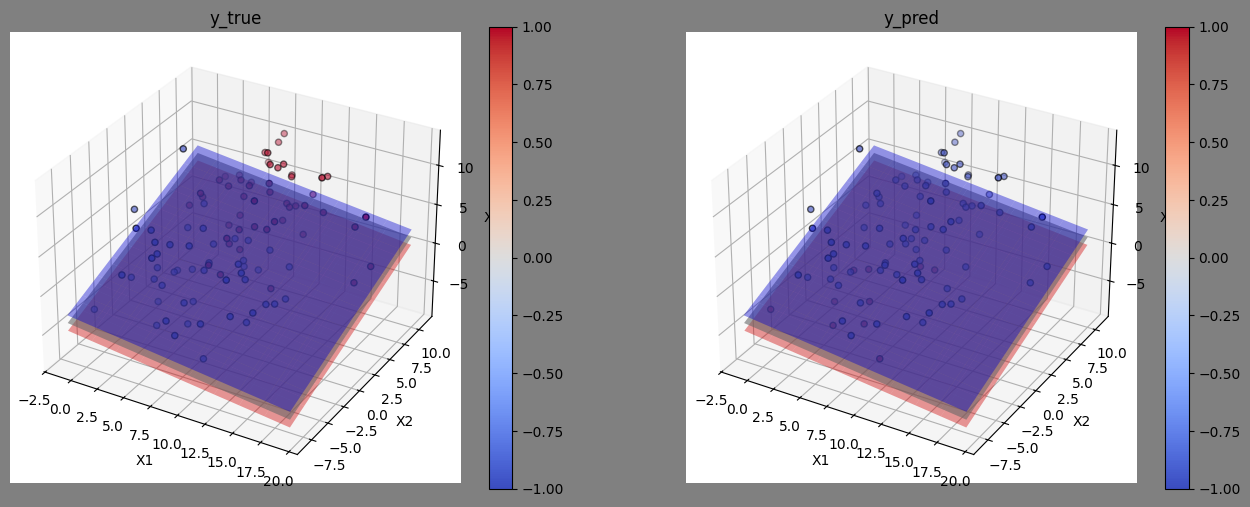

In [18]:
np.random.seed(1)
w = np.random.rand(3,)* 2 - 1
b = np.random.rand()* 2 - 1
print(w, b)

x, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, n_features=3, random_state=32)
x.shape, y.shape, x[:5], y[:5]
y= y * 2. - 1
plot_tvp_3d(x, y, w, b)

In [19]:
epochs = 100000
L = 0.0001

for i in range(epochs):
    w, b = gradient_descent(x, y, w, b, l=L)
    if i % 5000 == 4999:
        print(f"Epoch: {i+1:05d} | w1: {w[0]:.4f} | w2: {w[1]:.4f} | w3: {w[2]:.4f} | b: {b:.4f} | Loss: {loss(x, y, w, b):.4f}")
print(f"Score: {sum(predict(x, w, b) == y) / len(y)}")

Epoch: 05000 | w1: 0.0045 | w2: 0.4305 | w3: -0.0125 | b: -0.3899 | Loss: 0.4853
Epoch: 10000 | w1: -0.0142 | w2: 0.2608 | w3: 0.1007 | b: -0.4261 | Loss: 0.3780
Epoch: 15000 | w1: -0.0145 | w2: 0.2440 | w3: 0.1140 | b: -0.4692 | Loss: 0.3732
Epoch: 20000 | w1: -0.0117 | w2: 0.2360 | w3: 0.1175 | b: -0.5120 | Loss: 0.3693
Epoch: 25000 | w1: -0.0087 | w2: 0.2352 | w3: 0.1178 | b: -0.5518 | Loss: 0.3661
Epoch: 30000 | w1: -0.0057 | w2: 0.2369 | w3: 0.1193 | b: -0.5894 | Loss: 0.3632
Epoch: 35000 | w1: -0.0033 | w2: 0.2350 | w3: 0.1190 | b: -0.6245 | Loss: 0.3607
Epoch: 40000 | w1: -0.0009 | w2: 0.2331 | w3: 0.1186 | b: -0.6595 | Loss: 0.3583
Epoch: 45000 | w1: 0.0015 | w2: 0.2313 | w3: 0.1182 | b: -0.6933 | Loss: 0.3559
Epoch: 50000 | w1: 0.0037 | w2: 0.2296 | w3: 0.1179 | b: -0.7249 | Loss: 0.3539
Epoch: 55000 | w1: 0.0059 | w2: 0.2282 | w3: 0.1174 | b: -0.7563 | Loss: 0.3519
Epoch: 60000 | w1: 0.0082 | w2: 0.2293 | w3: 0.1159 | b: -0.7869 | Loss: 0.3500
Epoch: 65000 | w1: 0.0104 | w2: 

In [20]:
w, b

(array([0.0246977 , 0.22835769, 0.12901683]), -0.9993418547356576)

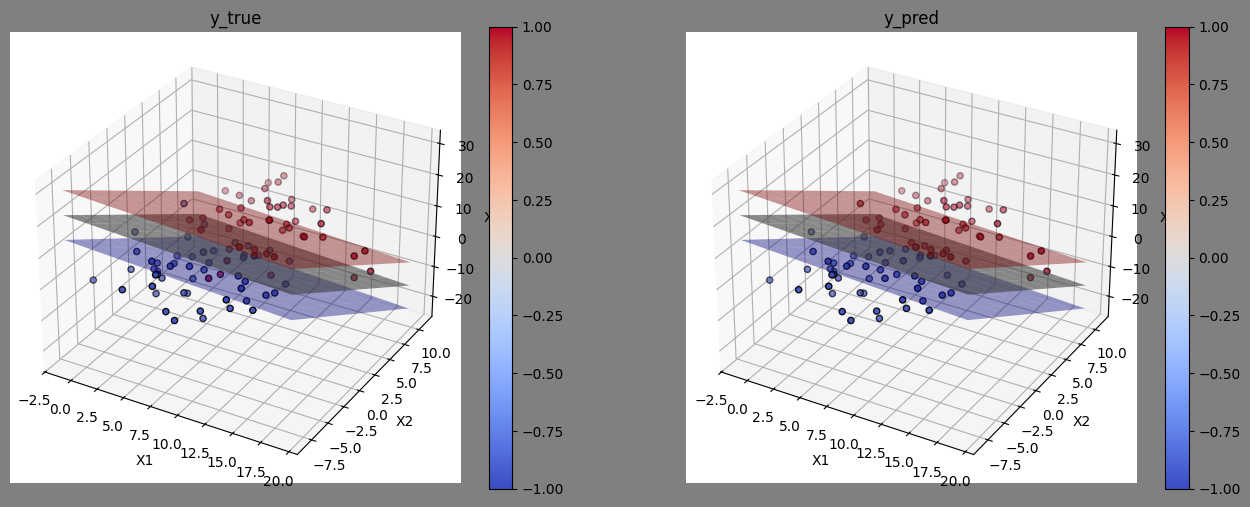

In [21]:
plot_tvp_3d(x, y, w, b)

# Polynomial Kernel
## (a dot b + r)^d

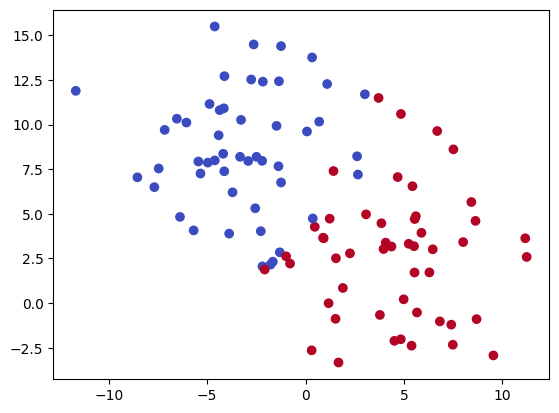

In [22]:
np.random.seed(189)
w = np.random.rand(100,)* 2 - 1
b = np.random.rand()* 2 - 1
#print(w, b)

x, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, random_state=42)
x.shape, y.shape, x[:5], y[:5]
y= y * 2. - 1
plt.scatter(x=x[:, 0], y=x[:, 1], c=y, cmap='coolwarm')

In [23]:
def polynomial_kernel(X, d, c=1):
    # This calculates (X dot X_T + c)^d for all pairs of points at once
    return (np.dot(X, X.T) + c) ** d

mean = np.mean(x, axis=0)
std = np.std(x, axis=0)

# Apply the transformation
x_scaled = (x - mean) / std

gram_matrix = polynomial_kernel(x_scaled, d=2)

In [24]:
epochs = 1000000
L = 0.000005

for i in range(epochs):
    w, b = gradient_descent(gram_matrix, y, w, b, l=L)
    if i % 50000 == 49999:
        print(f"Epoch: {i+1:05d} | b: {b:.4f} | Loss: {loss(gram_matrix, y, w, b):.4f}")

Epoch: 50000 | b: 0.1772 | Loss: 9.5891
Epoch: 100000 | b: 0.1769 | Loss: 5.8715
Epoch: 150000 | b: 0.1770 | Loss: 3.6192
Epoch: 200000 | b: 0.1770 | Loss: 2.2531
Epoch: 250000 | b: 0.1771 | Loss: 1.4245
Epoch: 300000 | b: 0.1771 | Loss: 0.9219
Epoch: 350000 | b: 0.1772 | Loss: 0.6171
Epoch: 400000 | b: 0.1772 | Loss: 0.4322
Epoch: 450000 | b: 0.1773 | Loss: 0.3201
Epoch: 500000 | b: 0.1773 | Loss: 0.2520
Epoch: 550000 | b: 0.1774 | Loss: 0.2108
Epoch: 600000 | b: 0.1774 | Loss: 0.1858
Epoch: 650000 | b: 0.1775 | Loss: 0.1706
Epoch: 700000 | b: 0.1775 | Loss: 0.1614
Epoch: 750000 | b: 0.1776 | Loss: 0.1558
Epoch: 800000 | b: 0.1776 | Loss: 0.1524
Epoch: 850000 | b: 0.1777 | Loss: 0.1504
Epoch: 900000 | b: 0.1777 | Loss: 0.1491
Epoch: 950000 | b: 0.1778 | Loss: 0.1484
Epoch: 1000000 | b: 0.1778 | Loss: 0.1479


In [29]:
print(f"Score: {sum(predict(gram_matrix, w, b) == y) / len(y)}")

Score: 0.91


# Radial RBF Kernel
## e^(-g(a-b)^2)

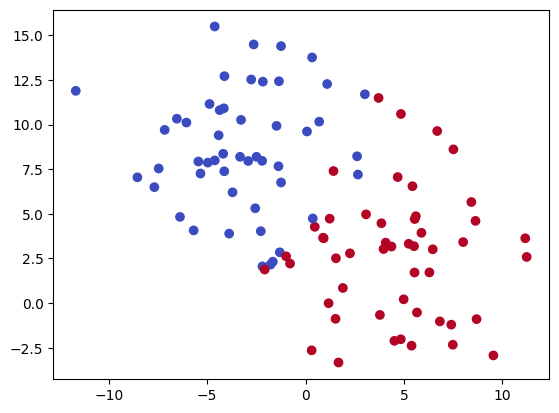

In [26]:
np.random.seed(189)
w = np.random.rand(100,)* 2 - 1
b = np.random.rand()* 2 - 1
#print(w, b)

x, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, random_state=42)
x.shape, y.shape, x[:5], y[:5]
y= y * 2. - 1
plt.scatter(x=x[:, 0], y=x[:, 1], c=y, cmap='coolwarm')

In [27]:
def radial_kernel(X, g=None):
    if g is None:
        g = 1 / (x.shape[1] * x.var())
        
    # This calculates e^(-g(a-b)^2) for all pairs of points at once
    sq_norms = np.sum(X**2, axis=1) # ||x||^2 for each point
    dot_product = np.dot(X, X.T) # nxn dot products
    
    # Use broadcasting to compute: ||x||^2 + ||y||^2 - 2(x * y)
    # np.reshape converts sq_norms to a column so it broadcasts across rows
    dists_sq = sq_norms[:, np.newaxis] + sq_norms - 2 * dot_product
    return np.exp(-g * dists_sq)

gram_matrix = radial_kernel(x)

In [32]:
epochs = 1000000
L = 0.0005

for i in range(epochs):
    w, b = gradient_descent(gram_matrix, y, w, b, l=L)
    if i % 50000 == 49999:
        print(f"Epoch: {i+1:05d} | b: {b:.4f} | Loss: {loss(gram_matrix, y, w, b):.4f}")

Epoch: 50000 | b: 0.3855 | Loss: 0.5835
Epoch: 100000 | b: 0.6094 | Loss: 0.5814
Epoch: 150000 | b: 0.7522 | Loss: 0.5806
Epoch: 200000 | b: 0.8428 | Loss: 0.5802
Epoch: 250000 | b: 0.9003 | Loss: 0.5801
Epoch: 300000 | b: 0.9368 | Loss: 0.5800
Epoch: 350000 | b: 0.9600 | Loss: 0.5800
Epoch: 400000 | b: 0.9746 | Loss: 0.5800
Epoch: 450000 | b: 0.9840 | Loss: 0.5800
Epoch: 500000 | b: 0.9899 | Loss: 0.5800
Epoch: 550000 | b: 0.9936 | Loss: 0.5800
Epoch: 600000 | b: 0.9960 | Loss: 0.5800
Epoch: 650000 | b: 0.9975 | Loss: 0.5800
Epoch: 700000 | b: 0.9985 | Loss: 0.5800
Epoch: 750000 | b: 0.9991 | Loss: 0.5800
Epoch: 800000 | b: 0.9995 | Loss: 0.5800
Epoch: 850000 | b: 0.9997 | Loss: 0.5800
Epoch: 900000 | b: 0.9999 | Loss: 0.5800
Epoch: 950000 | b: 0.9999 | Loss: 0.5800
Epoch: 1000000 | b: 1.0000 | Loss: 0.5800


In [33]:
print(f"Score: {sum(predict(gram_matrix, w, b) == y) / len(y)}")

Score: 0.42


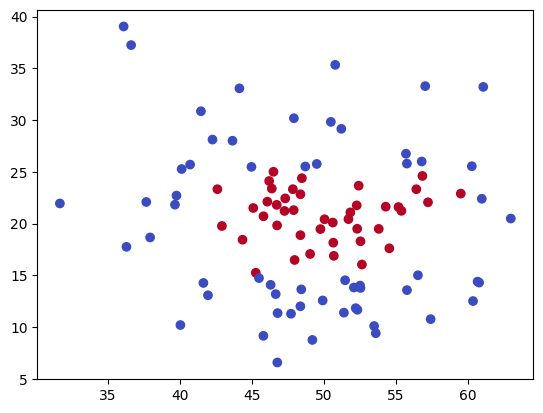

In [31]:
np.random.seed(42)
x = np.hstack((np.random.normal(loc=50, scale=7, size=(100, 1)), np.random.normal(loc=20, scale=7, size=(100, 1))))
y = ((x[:, 0] > 40) & (x[:, 0] < 60) & (x[:, 1] > 15) & (x[:, 1] < 25)).astype(int)
plt.scatter(x=x[:, 0], y=x[:, 1], c=y, cmap='coolwarm')
gram_matrix = radial_kernel(x)